# Цель исследования
Проверить, поддерживают ли учебные данные решение о выпуске новой страницы на основании увеличения конверсии. Это не промышленный эксперимент, проведённый мной в Яндексе.

H0: p_B ≤ p_A; H1: p_B > p_A. Односторонний z-тест, α = 0.05; расчёт на границе H0: p_B = p_A.

Метрика — доля пользователей с converted = 1 хотя бы в одной сохранённой записи. Значение события, протокол назначения групп и общее окно наблюдения требуют подтверждения по документации источника.

In [1]:
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportions_ztest,  proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
df_ab = pd.read_csv("ab_data.csv")
df_countries = pd.read_csv("countries.csv")

print(df_ab.info())
print()
print(df_countries.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294480 entries, 0 to 294479
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294480 non-null  int64 
 1   timestamp     294480 non-null  object
 2   group         294480 non-null  object
 3   landing_page  294480 non-null  object
 4   converted     294480 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB
None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290586 entries, 0 to 290585
Data columns (total 2 columns):
 #   Column   Non-Null Count   Dtype 
---  ------   --------------   ----- 
 0   user_id  290586 non-null  int64 
 1   country  290586 non-null  object
dtypes: int64(1), object(1)
memory usage: 4.4+ MB
None


Разница числа строк двух файлов сама по себе не показывает наличие пропущенных стран. Ниже проверим уникальность ключа countries и покрытие пользователей после соединения.

In [4]:
#голова таблицы ab_data
df_ab.head()

,user_id,timestamp,group,landing_page,converted
0,851104,11:48.6,control,old_page,0
1,804228,01:45.2,control,old_page,0
2,661590,55:06.2,treatment,new_page,0
3,853541,28:03.1,treatment,new_page,0
4,864975,52:26.2,control,old_page,1


In [5]:
#голова таблицы countries
df_countries.head()

,user_id,country
0,834778,UK
1,928468,US
2,822059,UK
3,711597,UK
4,710616,UK


In [6]:
print(f'Полных дубликатов в countries: {df_countries.duplicated().sum()}')
# Удаляем только идентичные записи страны; конфликтующие значения останавливают анализ.
df_countries = df_countries.drop_duplicates()
assert df_countries['user_id'].is_unique, 'Повторяющиеся user_id в countries размножат строки'
assert df_ab[['user_id','group','landing_page','converted']].notna().all().all()
assert set(df_ab['converted'].unique()) <= {0,1}
assert set(df_ab['group'].unique()) == {'control','treatment'}
df = pd.merge(df_ab, df_countries, on='user_id', how='left', validate='many_to_one')
raw = df.copy()
raw_group_counts = raw.groupby('user_id')['group'].nunique()
raw_cross_group_users = raw_group_counts[raw_group_counts > 1].index
print(f'Исходных строк: {len(raw):,}; пользователей в обеих группах: {len(raw_cross_group_users):,}')
print(f'Пользователей без страны: {raw.loc[raw.country.isna(), "user_id"].nunique():,}')

Полных дубликатов в countries: 1


Исходных строк: 294,480; пользователей в обеих группах: 1,895
Пользователей без страны: 0


In [7]:
pd.crosstab(df['group'], df['landing_page'])

landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145313,1965


In [8]:
wrong_rows = df[
    ((df['group'] == 'control') & (df['landing_page'] != 'old_page')) |
    ((df['group'] == 'treatment') & (df['landing_page'] != 'new_page'))
]

print(len(wrong_rows))

3893


In [9]:
wrong_rows.head()

,user_id,timestamp,group,landing_page,converted,country
22,767017,58:15.0,control,new_page,0,US
240,733976,11:16.4,control,new_page,0,US
308,857184,34:59.8,treatment,old_page,0,US
327,686623,26:40.7,treatment,old_page,0,US
357,856078,29:30.4,treatment,old_page,0,US


In [10]:
df = df.drop(wrong_rows.index)

In [11]:
users_in_both = df.groupby('user_id')['group'].nunique()
problem_users = users_in_both[users_in_both > 1]
print(problem_users)
print(problem_users.count()/users_in_both.count())

Series([], Name: group, dtype: int64)
0.0


В исходных данных 1 895 пользователей встречаются в обеих группах; это проверено до фильтрации. После удаления 3 893 строк с несовпадением группы и страницы такие пользователи перестают обнаруживаться как участники обеих групп.

Для сопоставимости сохраняем исходный порядок очистки как одну спецификацию. Ниже отдельно проверим результат при исключении всех исходных пользователей обеих групп. Ни один вариант автоматически не восстанавливает корректный причинный эффект: причина несовпадений неизвестна, а фильтрация может внести смещение.

In [12]:
df = df[~df['user_id'].isin(problem_users.index)]

In [13]:
print(f"CONTROL COUNT: {df[df['group'] == 'control']['user_id'].count()}")
print(f"CONTROL UNIQUE: {df[df['group'] == 'control']['user_id'].nunique()}")
print(f"TEST COUNT: {df[df['group'] == 'treatment']['user_id'].count()}")
print(f"TEST UNIQUE: {df[df['group'] == 'treatment']['user_id'].nunique()}")

CONTROL COUNT: 145274
CONTROL UNIQUE: 145274
TEST COUNT: 145313
TEST UNIQUE: 145311


Есть повторяющиеся записи пользователей; это не обязательно повторные визиты — возможны дубликаты логирования. Для пользовательской метрики агрегируем converted через max. Для причинной интерпретации нужны единое окно конверсии и правила учёта повторных событий.

In [14]:
df_user = df.groupby('user_id').agg({
    'user_id': 'first',
    'group': 'first',
    'timestamp': 'first',
    'country': 'first',
    'landing_page': 'first',
    'converted': 'max'
})
print(df_user.info())
df_user.head()

<class 'pandas.core.frame.DataFrame'>
Index: 290585 entries, 630000 to 945999
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       290585 non-null  int64 
 1   group         290585 non-null  object
 2   timestamp     290585 non-null  object
 3   country       290585 non-null  object
 4   landing_page  290585 non-null  object
 5   converted     290585 non-null  int64 
dtypes: int64(2), object(4)
memory usage: 15.5+ MB
None


,user_id,group,timestamp,country,landing_page,converted
user_id,,,,,,
630000,630000,treatment,26:06.5,US,new_page,0
630001,630001,treatment,16:42.6,US,new_page,1
630002,630002,control,20:56.4,US,old_page,0
630003,630003,treatment,09:31.5,US,new_page,0
630004,630004,treatment,23:58.8,US,new_page,0


Размеры очищенных групп близки, но это не доказывает корректность распределения. Проверка ожидаемой пропорции групп требует протокола рандомизации; фильтрация могла изменить исходный состав.

## Ретроспективная чувствительность
Оценим MDE при α = 0.05, мощности 80% и наблюдаемом размере групп для одностороннего теста. Это условный ориентир при текущей базовой конверсии, а не предварительный дизайн или фактическая мощность завершённого эксперимента.

In [15]:
ALPHA = 0.05
POWER = 0.8
baseline = df_user.loc[df_user['group']=='control','converted'].mean()
n = (df_user['group']=='control').sum()
ratio = (df_user['group']=='treatment').sum()/n
analysis = NormalIndPower()
from scipy.optimize import brentq
mde = brentq(lambda d: analysis.power(
    abs(proportion_effectsize(baseline, baseline+d)), nobs1=n,
    alpha=ALPHA, ratio=ratio, alternative='larger')-POWER,
    1e-9, 1-baseline-1e-9)
print(f'Ретроспективный MDE для увеличения: {mde*100:.3f} п.п.')

Ретроспективный MDE для увеличения: 0.302 п.п.


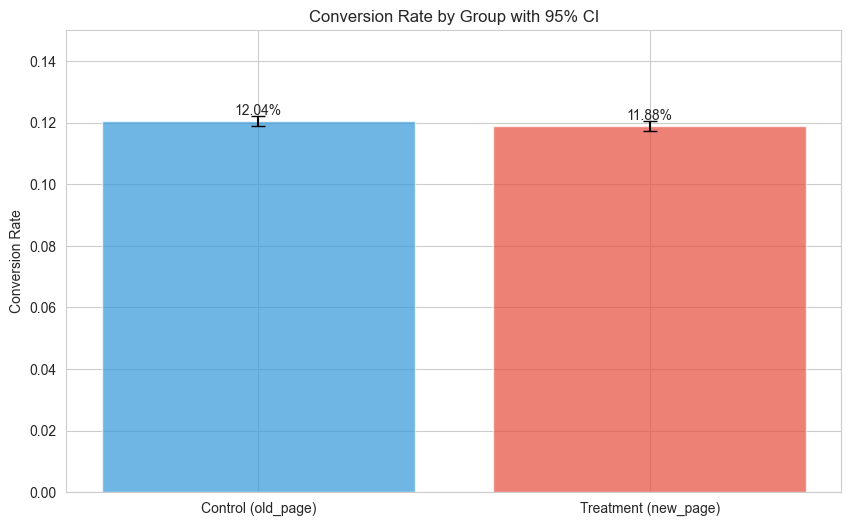

In [16]:
def get_conversion_ci(group_df):
    conv = group_df['converted'].mean()
    n = len(group_df)
    success = group_df['converted'].sum()
    ci_low, ci_high = proportion_confint(success, n, alpha=0.05, method='wilson')
    return conv, ci_low, ci_high

control_conv, control_low, control_high = get_conversion_ci(df_user[df_user['group'] == 'control'])
treat_conv, treat_low, treat_high = get_conversion_ci(df_user[df_user['group'] == 'treatment'])

fig, ax = plt.subplots()
groups = ['Control (old_page)', 'Treatment (new_page)']
convs = [control_conv, treat_conv]
errors = [[control_conv - control_low, treat_conv - treat_low],
          [control_high - control_conv, treat_high - treat_conv]]

ax.bar(groups, convs, yerr=errors, capsize=5, color=['#3498db', '#e74c3c'], alpha=0.7)
ax.set_ylabel('Conversion Rate')
ax.set_title('Conversion Rate by Group with 95% CI')
ax.set_ylim(0, 0.15)

for i, (conv, low, high) in enumerate([(control_conv, control_low, control_high),
                                        (treat_conv, treat_low, treat_high)]):
    ax.text(i, conv + 0.002, f'{conv:.2%}', ha='center')

plt.show()

Теперь можем провести статистический тест чтобы оценить значимость эффекта, в данном случае я буду использовать Z-test для долей.

In [17]:
print(f"A conversion mean: {df_user.loc[df_user['group'] == 'control']['converted'].mean()}")
print(f"B conversion mean: {df_user.loc[df_user['group'] == 'treatment']['converted'].mean()}")

A conversion mean: 0.1203863045004612
B conversion mean: 0.11880724790277405


In [18]:
group_a = df_user.loc[df_user['group'] == 'control']
group_b = df_user.loc[df_user['group'] == 'treatment']

count = [group_b['converted'].sum(), group_a['converted'].sum()]
nobs = [len(group_b), len(group_a)]

z_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative='larger')

print(f"z-статистика: {z_stat}; p-value: {p_value}")
if p_value < ALPHA:
    print("p-value < alpha, следовательно мы можем отвергнуть H0")
else:
    print("p-value >= alpha, следовательно мы не можем отвергнуть H0")

z-статистика: -1.3116075339133115; p-value: 0.905173705140591
p-value >= alpha, следовательно мы не можем отвергнуть H0


При α = 0.05 увеличение конверсии не подтверждено. Это не доказывает эквивалентность версий. Сегменты ниже рассматриваем как разведочный анализ, а не поиск положительного результата для замены основного вывода.

## Сегментный анализ

In [19]:
df_user.groupby('group')['country'].value_counts(normalize=True)

group      country
control    US         0.700167
           UK         0.250286
           CA         0.049548
treatment  US         0.701282
           UK         0.248474
           CA         0.050244
Name: proportion, dtype: float64

Состав групп по странам показан выше. Отдельные тесты по странам — разведочные, без поправки на множественные сравнения; они не проверяют равенство эффектов между странами.

In [20]:
#US
group_a_us = group_a.loc[group_a['country'] == 'US']
group_b_us = group_b.loc[group_b['country'] == 'US']

count = [group_b_us['converted'].sum(), group_a_us['converted'].sum()]
nobs = [len(group_b_us), len(group_a_us)]

z_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative='larger')

print(f"z-статистика: {z_stat}; p-value: {p_value}")
if p_value < ALPHA:
    print("p-value < alpha, следовательно мы можем отвергнуть H0")
else:
    print("p-value >= alpha, следовательно мы не можем отвергнуть H0")

z-статистика: -1.5060088024902438; p-value: 0.9339675430010533
p-value >= alpha, следовательно мы не можем отвергнуть H0


In [21]:
#UK
group_a_uk = group_a.loc[group_a['country'] == 'UK']
group_b_uk = group_b.loc[group_b['country'] == 'UK']

count = [group_b_uk['converted'].sum(), group_a_uk['converted'].sum()]
nobs = [len(group_b_uk), len(group_a_uk)]

z_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative='larger')

print(f"z-статистика: {z_stat}; p-value: {p_value}")
if p_value < ALPHA:
    print("p-value < alpha, следовательно мы можем отвергнуть H0")
else:
    print("p-value >= alpha, следовательно мы не можем отвергнуть H0")

z-статистика: 0.4748911128778919; p-value: 0.3174322930960848
p-value >= alpha, следовательно мы не можем отвергнуть H0


In [22]:
#CA
group_a_ca = group_a.loc[group_a['country'] == 'CA']
group_b_ca = group_b.loc[group_b['country'] == 'CA']

count = [group_b_ca['converted'].sum(), group_a_ca['converted'].sum()]
nobs = [len(group_b_ca), len(group_a_ca)]

z_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative='larger')

print(f"z-статистика: {z_stat}; p-value: {p_value}")
if p_value < ALPHA:
    print("p-value < alpha, следовательно мы можем отвергнуть H0")
else:
    print("p-value >= alpha, следовательно мы не можем отвергнуть H0")

z-статистика: -1.2968998972345893; p-value: 0.9026671840573587
p-value >= alpha, следовательно мы не можем отвергнуть H0


Ни в одной из показанных стран односторонний тест не обнаружил статистически значимого увеличения конверсии. Это не означает нулевой эффект в каждой стране или одинаковый эффект между странами.

# Вывод и рекомендация
В исходной спецификации очистки 290 585 пользователей: конверсия контроля 12.04%, новой страницы — 11.88%. Разница B − A составляет −0.158 п.п.; односторонний p-value для увеличения — 0.905. Приближённый двусторонний 95% интервал разницы: от −0.394 до +0.078 п.п.

При исключении всех 1 895 пользователей, встречавшихся в обеих группах до очистки, остаётся 288 690 пользователей. Разница — −0.147 п.п., односторонний p-value — 0.889. Вывод об отсутствии оснований утверждать увеличение сохраняется. Расчёты обеих спецификаций приведены ниже.

Данные не поддерживают выпуск новой страницы ради роста конверсии. Эквивалентность версий не доказана, а проблемы назначения групп ограничивают причинную интерпретацию.

Прежде чем планировать новый эксперимент, нужно разобраться с логированием группы и страницы, выбрать минимальный полезный для бизнеса эффект и защитные метрики, задать размер выборки и правило остановки. Продлевать текущий тест только до появления значимости некорректно.

In [23]:
# Сопоставление двух правил очистки и интервал разницы
from scipy.stats import norm
valid = ((raw['group']=='control') & (raw['landing_page']=='old_page')) | ((raw['group']=='treatment') & (raw['landing_page']=='new_page'))
sensitivity = raw.loc[valid & ~raw['user_id'].isin(raw_cross_group_users)]
sensitivity_user = sensitivity.groupby('user_id', as_index=False).agg(group=('group','first'), converted=('converted','max'))
def summarize(frame, label):
    a = frame.loc[frame['group']=='control','converted']
    b = frame.loc[frame['group']=='treatment','converted']
    delta = b.mean()-a.mean()
    se = np.sqrt(a.mean()*(1-a.mean())/len(a)+b.mean()*(1-b.mean())/len(b))
    _, p = proportions_ztest([b.sum(),a.sum()],[len(b),len(a)],alternative='larger')
    return {'analysis':label,'users':len(frame),'control_pct':a.mean()*100,'treatment_pct':b.mean()*100,
            'difference_pp':delta*100,'ci95_low_pp':(delta-norm.ppf(.975)*se)*100,
            'ci95_high_pp':(delta+norm.ppf(.975)*se)*100,'p_increase':p}
results = pd.DataFrame([summarize(df_user,'Исходный порядок'),summarize(sensitivity_user,'Исключение исходных cross-group')])
print(results.to_string(index=False))
print('95% интервалы двусторонние с непулированной SE; тест увеличения односторонний с пулированной SE.')

                       analysis  users  control_pct  treatment_pct  difference_pp  ci95_low_pp  ci95_high_pp  p_increase
               Исходный порядок 290585    12.038630      11.880725      -0.157906    -0.393867      0.078056    0.905174
Исключение исходных cross-group 288690    12.030492      11.883094      -0.147398    -0.384108      0.089312    0.888854
95% интервалы двусторонние с непулированной SE; тест увеличения односторонний с пулированной SE.
